## Evaluation on the test data

- Each model uses the threshold it chose on validation; nothing is tuned on test.
- The main view is test_main. test_full adds the late tail (59% laundering), so it looks better than it is.
- Run `python scripts/run_evaluation.py` first. It creates the tables and scores used here.

In [1]:
# find the project folder, import libraries
import sys
import json
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "priyanka" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, classification_report, precision_recall_curve
from src.models.data import load_modelling_frame

# folder with the results tables and short names for the chart
EVAL = PROJECT_ROOT / "artifacts" / "evaluation"
MODELS = ["logistic_regression", "naive_bayes", "decision_tree"]
NAMES = {
    "always_legitimate": "Always legitimate",
    "ach_rule": "ACH rule",
    "logistic_regression": "Logistic regression",
    "naive_bayes": "Naive Bayes",
    "decision_tree": "Decision tree",
}

In [2]:
# tables and scores saved by scripts/run_evaluation.py
results = pd.read_csv(EVAL / "results_table.csv", na_values="n/a")
budget = pd.read_csv(EVAL / "budget_table.csv")
patterns = pd.read_csv(EVAL / "pattern_recall.csv")
summary = json.load(open(EVAL / "evaluation_summary.json"))

scores = pd.read_csv(PROJECT_ROOT / "artifacts" / "scores" / "scores.csv")
test = scores[scores["split"] == "test_main"]
y = test["is_laundering"]

# thresholds chosen on validation; the two baselines use 1.0
thresholds = {"always_legitimate": 1.0, "ach_rule": 1.0}
for m in MODELS:
    thresholds[m] = summary["models"][m]["threshold"]

print(test.shape)
print(f"Laundering rate: {y.mean():.4%}")

(1014774, 9)
Laundering rate: 0.1126%


### 1. Results on the main test period

In [3]:
cols = ["model", "precision", "recall", "f1", "alert_fraction", "pr_auc", "roc_auc"]
results[results["test_view"] == "test_main"][cols].round(3)

,model,precision,recall,f1,alert_fraction,pr_auc,roc_auc
1,always_legitimate,NaN,0.000,0.000,0.000,0.001,0.500
4,ach_rule,0.007,0.874,0.014,0.136,0.006,0.869
7,logistic_regression,0.090,0.135,0.108,0.002,0.046,0.951
10,naive_bayes,0.065,0.059,0.062,0.001,0.012,0.901
13,decision_tree,0.224,0.197,0.210,0.001,0.123,0.772


### 2. Why not accuracy?
Laundering is about 0.1% of transactions, so a model that flags nothing is still 99.9% accurate.

In [4]:
rows = []
for model, threshold in thresholds.items():
    y_pred = (test[model] >= threshold).astype(int)
    rows.append({"model": model, "accuracy": accuracy_score(y, y_pred), "recall": recall_score(y, y_pred)})

pd.DataFrame(rows).round(4)

,model,accuracy,recall
0,always_legitimate,0.9989,0.0000
1,ach_rule,0.8647,0.8740
2,logistic_regression,0.9975,0.1347
3,naive_bayes,0.9980,0.0586
4,decision_tree,0.9983,0.1969


### 3. Confusion matrix (decision tree)

In [5]:
y_pred = (test["decision_tree"] >= thresholds["decision_tree"]).astype(int)

print(confusion_matrix(y, y_pred))
print(classification_report(y, y_pred, target_names=["legitimate", "laundering"], digits=3))

[[1012851     780]
 [    918     225]]
              precision    recall  f1-score   support

  legitimate      0.999     0.999     0.999   1013631
  laundering      0.224     0.197     0.209      1143

    accuracy                          0.998   1014774
   macro avg      0.611     0.598     0.604   1014774
weighted avg      0.998     0.998     0.998   1014774



### 4. Precision-recall curves
The dashed line is a model with no skill: its precision equals the laundering rate.

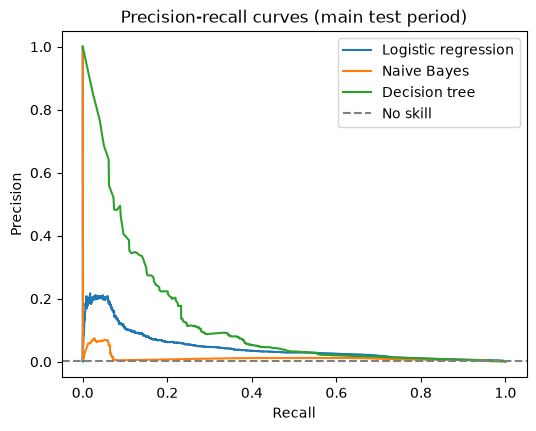

In [6]:
plt.figure(figsize=(6, 4.5))
for model in MODELS:
    precision, recall, _ = precision_recall_curve(y, test[model])
    plt.plot(recall, precision, label=NAMES[model])

plt.axhline(y.mean(), color="grey", linestyle="--", label="No skill")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curves (main test period)")
plt.legend()
plt.savefig(EVAL / "pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()

### 5. Recall at the 1% alert budget
Only the top 1% of scores get an alert. Rows tied at the cut-off share the remaining alerts evenly.

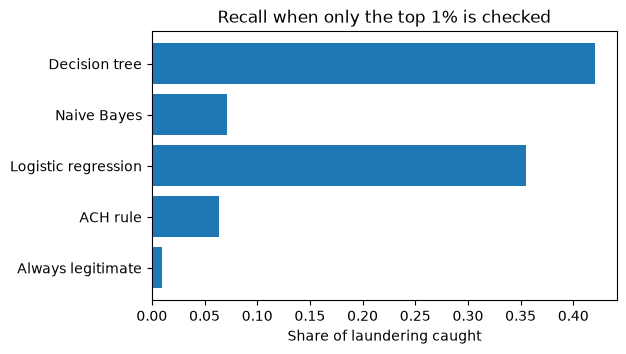

In [7]:
b = budget[budget["test_view"] == "test_main"]

plt.figure(figsize=(6, 3.5))
plt.barh([NAMES[m] for m in b["model"]], b["recall_at_budget"])
plt.xlabel("Share of laundering caught")
plt.title("Recall when only the top 1% is checked")
plt.savefig(EVAL / "budget_recall.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
b[["model", "alerts_allowed", "expected_caught", "recall_at_budget", "rows_tied_at_cutoff"]].round(3)

,model,alerts_allowed,expected_caught,recall_at_budget,rows_tied_at_cutoff
1,always_legitimate,10148,11.430,0.010,1014774
4,ach_rule,10148,73.388,0.064,138141
7,logistic_regression,10148,406.000,0.355,1
10,naive_bayes,10148,82.000,0.072,1
13,decision_tree,10148,480.406,0.420,133


### 6. Recall by laundering pattern
"none" is laundering that is not part of a named pattern.

In [9]:
p = patterns[(patterns["test_view"] == "test_main") & (patterns["model"].isin(MODELS))]

table = p.pivot(index="pattern_type", columns="model", values="recall")[MODELS]
table["laundering_rows"] = p.groupby("pattern_type")["laundering_rows"].first()
table.round(3)

model,logistic_regression,naive_bayes,decision_tree,laundering_rows
pattern_type,,,,
BIPARTITE,0.096,0.058,0.192,52
CYCLE,0.092,0.138,0.277,65
FAN-IN,0.465,0.042,0.394,71
FAN-OUT,0.149,0.162,0.324,74
GATHER-SCATTER,0.238,0.048,0.333,147
RANDOM,0.244,0.156,0.133,45
SCATTER-GATHER,0.333,0.089,0.439,123
STACK,0.075,0.047,0.271,107
none,0.009,0.022,0.015,459


### 7. Error analysis (decision tree)
Add the features back, then compare caught laundering (TP), missed laundering (FN) and false alarms (FP).

In [10]:
features = load_modelling_frame(PROJECT_ROOT / "data" / "processed", splits=("test_main",), allow_test=True)
errors = test.merge(features.drop(columns=["split", "is_laundering"]), on="transaction_id")

flagged = errors["decision_tree"] >= thresholds["decision_tree"]
laundering = errors["is_laundering"] == 1
errors["outcome"] = "TN"
errors.loc[flagged & laundering, "outcome"] = "TP"
errors.loc[~flagged & laundering, "outcome"] = "FN"
errors.loc[flagged & ~laundering, "outcome"] = "FP"

errors["outcome"].value_counts()

outcome
TN    1012851
FN        918
FP        780
TP        225
Name: count, dtype: int64

In [11]:
# payment format of each group (share of rows)
pd.crosstab(errors["outcome"], errors["payment_format"], normalize="index").round(3)

payment_format,ACH,Bitcoin,Cash,Cheque,Credit Card,Wire
outcome,,,,,,
FN,0.843,0.014,0.024,0.077,0.041,0.000
FP,1.000,0.000,0.000,0.000,0.000,0.000
TN,0.135,0.028,0.107,0.406,0.288,0.036
TP,1.000,0.000,0.000,0.000,0.000,0.000


In [12]:
# typical activity of each group (median)
activity = ["log_amount_paid", "sender_txn_count_24h", "sender_unique_receivers_24h",
            "receiver_txn_count_24h", "receiver_unique_senders_24h"]
errors.groupby("outcome")[activity].median().round(2)

,log_amount_paid,sender_txn_count_24h,sender_unique_receivers_24h,receiver_txn_count_24h,receiver_unique_senders_24h
outcome,,,,,
FN,8.67,0.0,0.0,1.0,1.0
FP,9.42,2.0,1.0,2.0,1.0
TN,7.13,4.0,2.0,2.0,1.0
TP,9.52,2.0,1.0,2.0,1.0


In [13]:
# examples of missed laundering
show = ["transaction_id", "pattern_type", "payment_format", "decision_tree"] + activity
errors[errors["outcome"] == "FN"][show].head()

,transaction_id,pattern_type,payment_format,decision_tree,log_amount_paid,sender_txn_count_24h,sender_unique_receivers_24h,receiver_txn_count_24h,receiver_unique_senders_24h
319,3459506,STACK,ACH,0.000000,10.949032,0,0,0,0
1307,3906800,SCATTER-GATHER,ACH,0.000000,12.474862,7,5,0,0
2273,3162467,FAN-OUT,ACH,0.993362,10.843586,19,10,0,0
2473,4064968,NaN,ACH,0.000000,7.482969,1,1,11,7
2624,2976950,FAN-OUT,ACH,0.979674,9.492381,0,0,3,1


In [14]:
# examples of false alarms
errors[errors["outcome"] == "FP"][show].head()

,transaction_id,pattern_type,payment_format,decision_tree,log_amount_paid,sender_txn_count_24h,sender_unique_receivers_24h,receiver_txn_count_24h,receiver_unique_senders_24h
107,4062971,NaN,ACH,0.995161,9.130020,2,1,2,1
1552,4066660,NaN,ACH,0.997196,13.496209,7,3,0,0
1826,4065467,NaN,ACH,0.994150,11.591155,0,0,2,1
2048,4062793,NaN,ACH,0.994498,9.282590,0,0,0,0
4721,4062099,NaN,ACH,0.994597,9.277437,0,0,1,1


### 8. Main Findings
- The decision tree is the best model on the main test period: PR-AUC 0.123 (no skill: 0.001), precision 0.22, recall 0.20.
- Accuracy is misleading: flagging nothing scores 99.89%, higher than the decision tree (99.83%).
- ROC-AUC favours logistic regression (0.95), but its PR-AUC is only 0.046, because ROC-AUC hides false alarms when laundering is rare.
- With a 1% review budget, the decision tree catches 42% of laundering, against 1% for random checking.
- The models catch named patterns (decision tree: 32%) but almost none of the laundering without a pattern (1.5%).
- Every alert from the decision tree is an ACH payment, so non-ACH laundering (16% of the missed cases) is never caught.
- Missed laundering often comes from accounts with no recent activity, and false alarms look almost the same as caught laundering on all 10 features.